# Cvičenie II - Lineárne modely a predikcia časových radov

## Predikcia s ARIMA modelmi

Modely Arima predstavujú široko používanú skupinu modelov na analýzu a predikciu stacionárnych časových radov.

### Lag v autokorelácii
Lag vyjadruje o koľko časových krokov porovnávame aktuálnu hodnotu s hodnotou z minulosti.

Napríklad:
- **lag 1**: porovnávame ($Y{_t}$) s ($Y_{t-1}$)
- **lag 2**: porovnávame ($Y{_t}$) s ($Y_{t-2}$)
- **lag 12**: aktuálnu hodnotu porovnávame s hodnotou spred 12 období

S lagmi sa stretávame pri autokorelácii, pretože autokorelácia meria, ako silno súvisí časový rad so svojimi vlastnými minulými hodnotami pri rôznych lagoch.

To nám pomáha odhaliť napríklad:

- krátkodobú závislosť medzi susednými pozorovaniami,
- opakujúce sa sezónne vzory,
- či minulé hodnoty obsahujú informáciu užitočnú pre predikciu.

---

#### Rozdiel medzi ACF a PACF: Celková vs. priama závislosť

<div align="center">
<img src="images/acf_vs_pacf.png" alt="ACF vs PACF perspektíva" width="480"/>
</div>

## ARIMA model

ARIMA kombinuje tri zložky – autoregresiu, diferencovanie a moving-average zložku.

### AR(p) – Autoregresná zložka

Autoregresná zložka modeluje vzťah medzi aktuálnym pozorovaním a jeho vlastnými minulými hodnotami:

$$X_t = c + \phi_1 X_{t-1} + \phi_2 X_{t-2} + \dots + \phi_p X_{t-p} + \varepsilon_t$$


Parameter \(p\) určuje, koľko minulých hodnôt priamo vstupuje do modelu.

### I(d) – Integrovaná zložka

Parameter \(d\) vyjadruje, koľkokrát časový rad diferencujeme, aby sme získali približne stacionárny rad.

Ak prvá diferencia vytvorí stacionárny rad, potom \(d=1\).

### MA(q) – Moving-average

MA zložka modeluje vzťah medzi aktuálnym pozorovaním a minulými náhodnými šokmi:

$$X_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \theta_2 \varepsilon_{t-2} + \dots + \theta_q \varepsilon_{t-q}$$

Parameter \(q\) určuje počet minulých inovácií, ktoré vstupujú do modelu.

--------
## 1. Príprava dát

In [ ]:
# TODO:
# 1. Načítajte INDPRO.csv.
# 2. Rozdeľte dáta v pomere 80/20 na trénovanie a testovanie - chronologicky.
# 3. Vykreslite dataset na grafe.

Missing values:
INDPRO    0
dtype: int64
Training data: 1980-01-01 - 2009-04-01
Testing data: 2009-05-01 - 2016-08-01


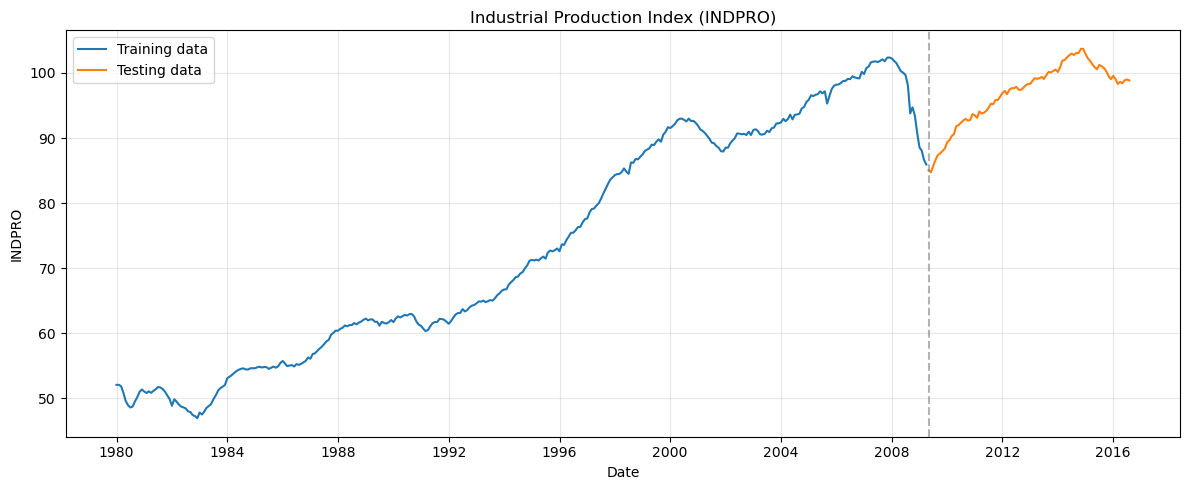

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("INDPRO.csv", index_col=0, parse_dates=True)
df = df.sort_index()

df = df.asfreq("MS")

print("Missing values:")
print(df.isna().sum())

split = int(len(df) * 0.8)
train = df.iloc[:split]
test = df.iloc[split:]

print(f"Training data: {train.index[0].date()} - {train.index[-1].date()}")
print(f"Testing data: {test.index[0].date()} - {test.index[-1].date()}")

plt.figure(figsize=(12, 5))
plt.plot(train.index, train["INDPRO"], label="Training data")
plt.plot(test.index, test["INDPRO"], label="Testing data")
plt.axvline(test.index[0], color="gray", linestyle="--", alpha=0.6)
plt.title("Industrial Production Index (INDPRO)")
plt.xlabel("Date")
plt.ylabel("INDPRO")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Validácia výberu parametrov ARIMA modelu

Správny model spoznáme tak, že: 

1. ACF a PACF lagy rezíduí ležia kompletne v pásme šumu bez vyčnievajúcich lagov (teda v reziduách sa nechádza žiadna signifikantná autokorelácia

2. Ljung-Boxov test potvrdzuje biely šum
    -   Nulová hypotéza: Reziduá sú nezávislé a identicky rozdelené
    -   $p > 0.05 \implies$ žiadna zvyšková autokorelácia

3. AIC/BIC dosahuje čo najnižšiu hodnotu - rovnováha medzi presnosťou na dátach a zložitosťou modelu
    -   AIC prioritou je presnosť predikcií
    -   BIC prioritou je hľadanie jednoduchého a robustného modelu
    
4. Reziduá sú približne normálne rozdelené (histogram/Q-Q graf).


In [8]:
# TODO:
# 1. Natrénujte model ARIMA(0,1,1) na tréningových dátach.
# 2. Vykreslite ACF reziduí vybraného modelu.
# 3. Vykonajte Ljung-Box test na lagoch 3, 6, 9 a 12
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

Training data: 1980-01-01 00:00:00 - 2009-04-01 00:00:00
Testing data: 2009-05-01 00:00:00 - 2016-08-01 00:00:00
                               SARIMAX Results                                
Dep. Variable:                 INDPRO   No. Observations:                  352
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -276.883
Date:                Wed, 21 Oct 2026   AIC                            557.766
Time:                        20:21:25   BIC                            565.487
Sample:                    01-01-1980   HQIC                           560.839
                         - 04-01-2009                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.2007      0.025      8.122      0.000       0.152       0.249
sigma2         0.2

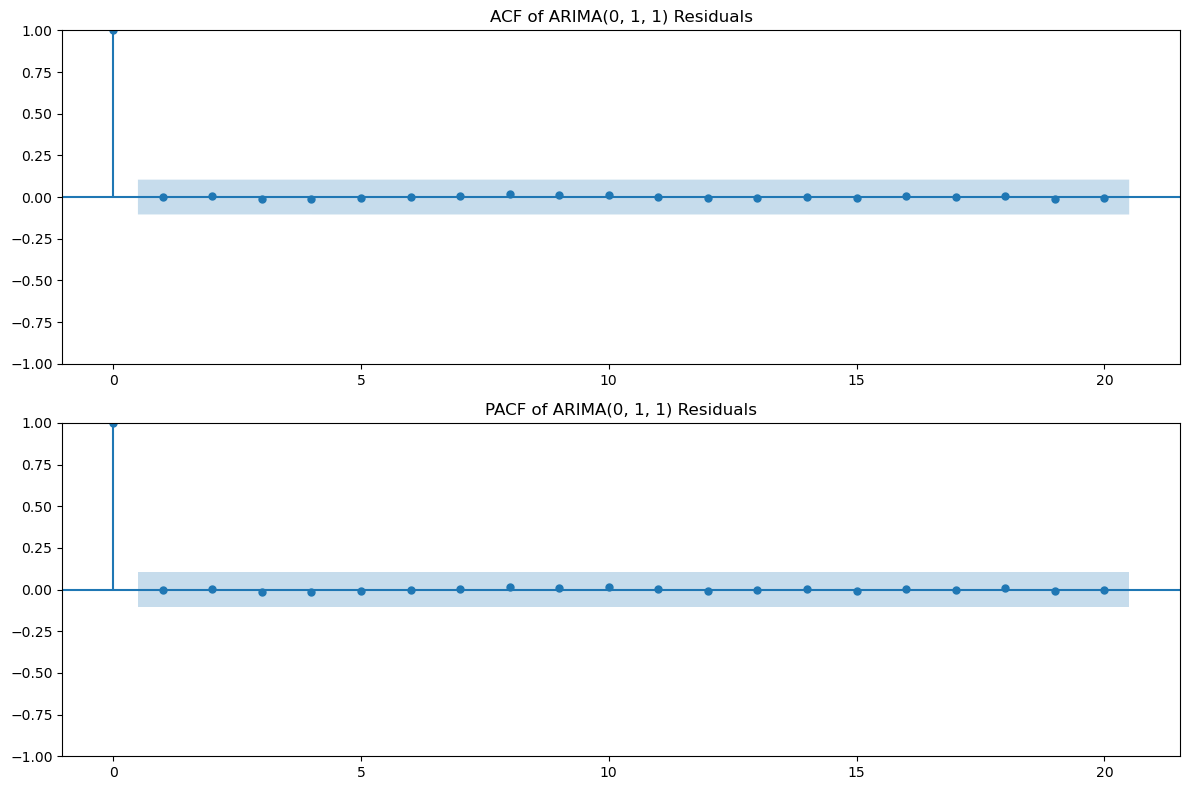

Ljung-Box Test Results:
     lb_stat  lb_pvalue
3   0.058844   0.971007
6   0.131416   0.999682
9   0.264279   0.999989
12  0.361797   1.000000
Lag 3: p-value = 0.9710 - No significant autocorrelation detected.
Lag 6: p-value = 0.9997 - No significant autocorrelation detected.
Lag 9: p-value = 1.0000 - No significant autocorrelation detected.
Lag 12: p-value = 1.0000 - No significant autocorrelation detected.


In [18]:
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

df = pd.read_csv("INDPRO.csv", index_col=0, parse_dates=True)
df = df.sort_index()

split = int(len(df) * 0.8)
train = df.iloc[:split]
test = df.iloc[split:]

print("Training data:", train.index.min(), "-", train.index.max())
print("Testing data:", test.index.min(), "-", test.index.max())

train_series = train["INDPRO"].copy()
train_series.index = pd.DatetimeIndex(train_series.index, freq="MS")

model = ARIMA(train_series, order=(0, 1, 1))
model_fit = model.fit()



print(model_fit.summary())

residuals = model_fit.resid

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(residuals, lags=20, ax=axes[0])
axes[0].set_title("ACF of ARIMA(0, 1, 1) Residuals")

plot_pacf(residuals, lags=20, ax=axes[1], method="ywm")
axes[1].set_title("PACF of ARIMA(0, 1, 1) Residuals")

plt.tight_layout()
plt.show()

ljung_box_results = acorr_ljungbox(
    residuals,
    lags=[3, 6, 9, 12],
    return_df=True,
    model_df=1
)

print("Ljung-Box Test Results:")
print(ljung_box_results)

for lag, row in ljung_box_results.iterrows():
    p_value = row["lb_pvalue"]

    if p_value > 0.05:
        print(f"Lag {lag}: p-value = {p_value:.4f} - No significant autocorrelation detected.")
    else:
        print(f"Lag {lag}: p-value = {p_value:.4f} - Significant autocorrelation detected.")


# 3. Hľadanie vhodnejšieho modelu
| Typ procesu | ACF graf | PACF graf | Voľba rádu |
| :--- | :--- | :--- | :--- |
| **AR($p$)** | Postupný pokles (tail off) | **Prudký pád po lagu $p$** (cut off) | $p$ = počet lagov pred pádom, $q = 0$ |
| **MA($q$)** | **Prudký pád po lagu $q$** (cut off) | Postupný pokles (tail off) | $p = 0$, $q$ = počet lagov pred pádom |
| **ARMA($p,q$)** | Postupný pokles | Postupný pokles | Kandidáti: kombinácie $p, q$ overené cez AIC/BIC |
| **Biely šum** | Všetky lagy v pásme šumu | Všetky lagy v pásme šumu | $p = 0, q = 0$ |

ADF Test on Original Series
ADF Statistic: -1.6513
P-value: 0.4563

Selected differencing order d: 1
ADF p-value after differencing: 0.0002


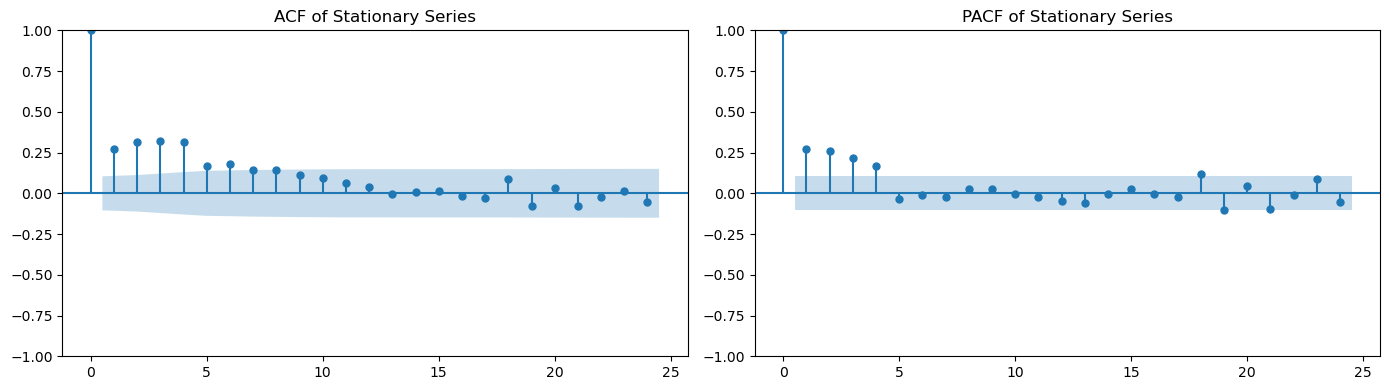


Grid Search Results (sorted by AIC)
 p  d  q        AIC        BIC
 1  1  2 489.548660 504.991805
 1  1  3 490.219824 509.523755
 3  1  1 490.539687 509.843618
 2  1  2 490.564846 509.868777
 2  1  1 490.786247 506.229392
 3  1  2 491.845232 515.009949
 2  1  3 492.218245 515.382963
 3  1  3 492.709302 519.734806
 1  1  1 493.976408 505.558767
 3  1  0 501.633067 517.076211
 2  1  0 519.766187 531.348545
 0  1  3 527.702217 543.145362
 0  1  2 543.734025 555.316383
 1  1  0 546.704592 554.426164
 0  1  1 557.765915 565.487487
 0  1  0 576.413616 580.274402

Best ARIMA order by AIC: (1, 1, 2)
AIC: 489.5487
BIC: 504.9918

Selected ARIMA Model Summary
                               SARIMAX Results                                
Dep. Variable:                 INDPRO   No. Observations:                  352
Model:                 ARIMA(1, 1, 2)   Log Likelihood                -240.774
Date:                Wed, 21 Oct 2026   AIC                            489.549
Time:                     

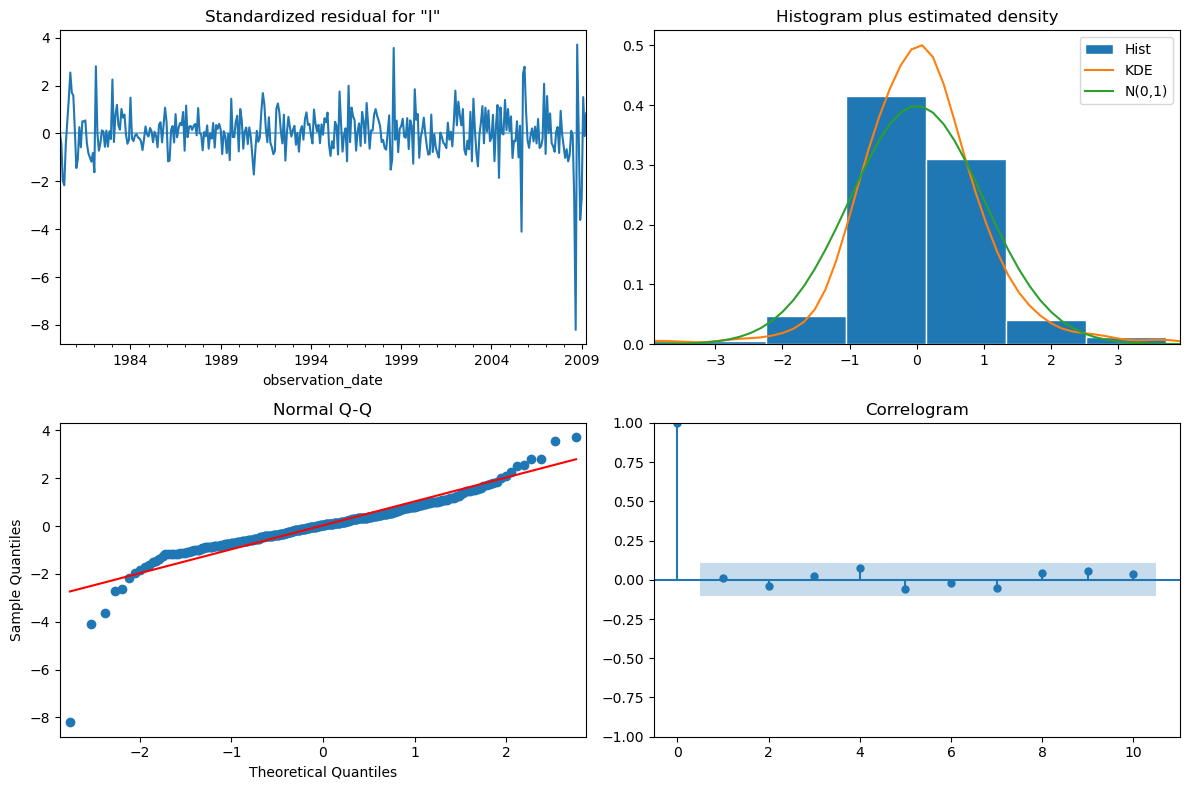


Ljung-Box Test Results
     lb_stat  lb_pvalue
6   0.259670   0.967426
12  0.750936   0.999829
18  0.843420   1.000000
24  1.133142   1.000000
Lag 6: No significant residual autocorrelation detected.
Lag 12: No significant residual autocorrelation detected.
Lag 18: No significant residual autocorrelation detected.
Lag 24: No significant residual autocorrelation detected.

auto_arima Results
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  352
Model:               SARIMAX(1, 1, 2)   Log Likelihood                -240.774
Date:                Wed, 21 Oct 2026   AIC                            489.549
Time:                        20:22:30   BIC                            504.992
Sample:                    01-01-1980   HQIC                           495.695
                         - 04-01-2009                                         
Covariance Type:                  opg               

In [19]:
# TODO:
# 1. Otestujte stacionaritu pomocou ADF testu. Ak rad nie je stacionárny, diferencujte ho a test zopakujte. Počet diferencií určuje parameter d.
# 2. Vykreslite ACF a PACF na návrh parametrov q a p.
# 3. Cez mriežkové vyhľadávanie (grid search) vypíšte a porovnajte AIC a BIC kandidátov.
# 4. Skontrolujte ACF reziduí zvoleného modelu cez plot_diagnostics().
# 5. Vykonajte Ljungov–Boxov test.
# 6. Porovnajte výber vášho modelu s použitím auto_arima, ktoré automatický zvolí najlepší model.
from pmdarima import auto_arima
import warnings
import itertools
import matplotlib.pyplot as plt
from pmdarima import auto_arima

warnings.filterwarnings("ignore")

y = train["INDPRO"].dropna().astype(float)
y.index = pd.DatetimeIndex(y.index, freq="MS")

adf_result = adfuller(y)

print("ADF Test on Original Series")
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"P-value: {adf_result[1]:.4f}")

d = 0
stationary_series = y.copy()

while adfuller(stationary_series)[1] > 0.05 and d < 2:
    stationary_series = stationary_series.diff().dropna()
    d += 1

print(f"\nSelected differencing order d: {d}")
print(f"ADF p-value after differencing: {adfuller(stationary_series)[1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(stationary_series, lags=24, ax=axes[0])
axes[0].set_title("ACF of Stationary Series")

plot_pacf(stationary_series, lags=24, ax=axes[1], method="ywm")
axes[1].set_title("PACF of Stationary Series")

plt.tight_layout()
plt.show()

p_values = range(0, 4)
q_values = range(0, 4)

results = []

for p, q in itertools.product(p_values, q_values):
    try:
        model = ARIMA(y, order=(p, d, q))
        fitted_model = model.fit()

        results.append({
            "p": p,
            "d": d,
            "q": q,
            "AIC": fitted_model.aic,
            "BIC": fitted_model.bic
        })
    except Exception as error:
        print(f"Model ARIMA({p},{d},{q}) failed: {error}")

results_df = pd.DataFrame(results).sort_values("AIC")

print("\nGrid Search Results (sorted by AIC)")
print(results_df.to_string(index=False))

best_row = results_df.loc[results_df["AIC"].idxmin()]
best_order = (int(best_row["p"]), int(best_row["d"]), int(best_row["q"]))

print(f"\nBest ARIMA order by AIC: {best_order}")
print(f"AIC: {best_row['AIC']:.4f}")
print(f"BIC: {best_row['BIC']:.4f}")

best_model = ARIMA(y, order=best_order).fit()

print("\nSelected ARIMA Model Summary")
print(best_model.summary())

best_model.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()

residuals = best_model.resid

lb_results = acorr_ljungbox(
    residuals,
    lags=[6, 12, 18, 24],
    model_df=best_order[0] + best_order[2],
    return_df=True
)

print("\nLjung-Box Test Results")
print(lb_results)

for lag, row in lb_results.iterrows():
    p_value = row["lb_pvalue"]

    if pd.notna(p_value) and p_value > 0.05:
        print(f"Lag {lag}: No significant residual autocorrelation detected.")
    else:
        print(f"Lag {lag}: Residual autocorrelation may remain.")

automatic_model = auto_arima(
    y,
    start_p=0,
    start_q=0,
    max_p=3,
    max_q=3,
    d=d,
    seasonal=False,
    information_criterion="aic",
    stepwise=True,
    suppress_warnings=True,
    error_action="ignore"
)

print("\nauto_arima Results")
print(automatic_model.summary())

print("\nModel Comparison")
print(f"Grid Search ARIMA order: {best_order}")
print(f"Grid Search AIC: {best_model.aic:.4f}")
print(f"Grid Search BIC: {best_model.bic:.4f}")
print(f"auto_arima order: {automatic_model.order}")
print(f"auto_arima AIC: {automatic_model.aic():.4f}")

if best_model.aic < automatic_model.aic():
    print("Grid search selected a model with a lower AIC.")
elif best_model.aic > automatic_model.aic():
    print("auto_arima selected a model with a lower AIC.")
else:
    print("Both methods achieved the same AIC.")


## 4. Evaluácia predikčnej schopnosti modelu pomocou Rolling-Origin

Rolling-Origin testuje ARIMA model opakovaným posúvaním (sliding) alebo rozširovaním (expanding) tréningového okna. 

<div align="center">
<img src="images/fixed-vs-rolling-window-time-series.png" alt="ACF vs PACF perspektíva" width="480"/>
</div>


Forecast Evaluation Results
                Model      MAE     RMSE
                ARIMA 0.389170 0.467612
                Naive 0.405332 0.485901
Exponential Smoothing 0.381327 0.516430


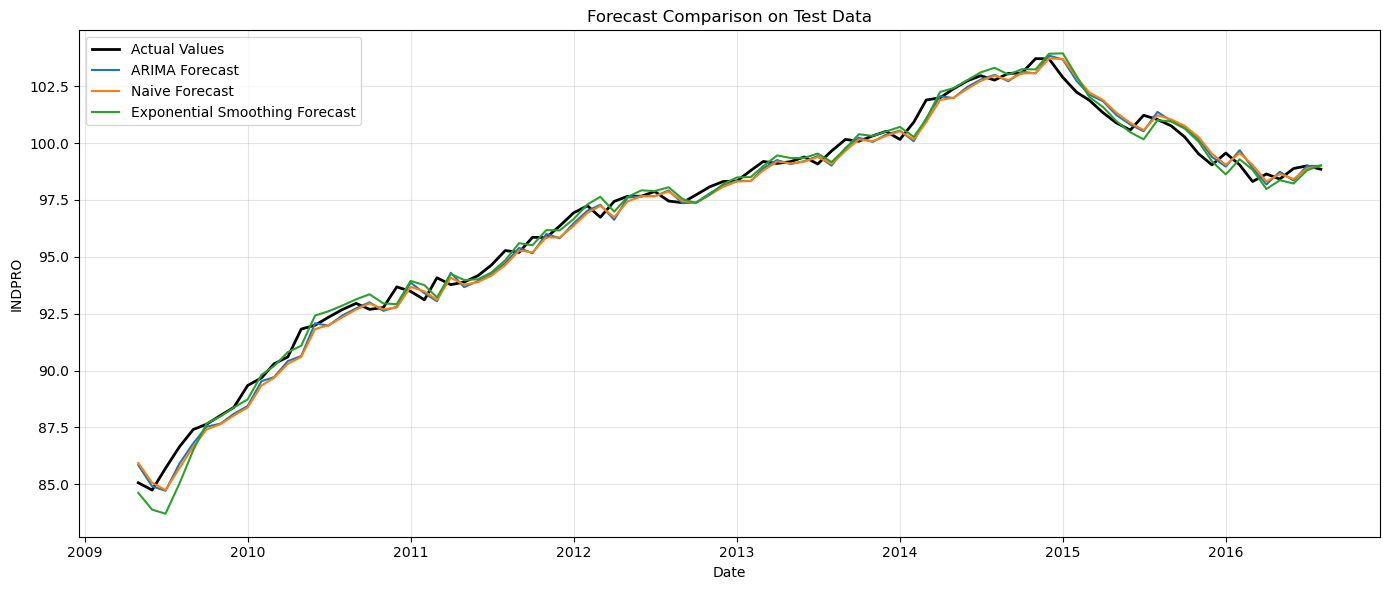

In [20]:
# TODO:
# 1. Evaluujte predikciu ARIMA modelu pomocou testovacích dát a posuvného okna.
# 2. Porovnajte výsledky ARIMA modelu s inými modelmi (Naive model, Exp Smoothing) pomocou MAE a RMSE
# 3. Vykreslite výsledky predikcií modelov na grafe

from statsmodels.tsa.holtwinters import ExponentialSmoothing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error
train_series = train["INDPRO"].dropna().astype(float)
test_series = test["INDPRO"].dropna().astype(float)

best_order = (0, 1, 1)

arima_predictions = []
naive_predictions = []
es_predictions = []

history = list(train_series)

for actual_value in test_series:
    # ARIMA forecast
    arima_model = ARIMA(history, order=best_order)
    arima_fit = arima_model.fit()
    arima_forecast = arima_fit.forecast(steps=1)[0]
    arima_predictions.append(arima_forecast)

    # Naive forecast
    naive_predictions.append(history[-1])

    # Exponential Smoothing forecast
    try:
        es_model = ExponentialSmoothing(
            history,
            trend="add",
            seasonal=None,
            initialization_method="estimated"
        )
        es_fit = es_model.fit()
        es_forecast = es_fit.forecast(steps=1)[0]
    except Exception:
        es_forecast = history[-1]

    es_predictions.append(es_forecast)

    # Update the history with the actual observation
    history.append(actual_value)

arima_predictions = pd.Series(arima_predictions, index=test_series.index)
naive_predictions = pd.Series(naive_predictions, index=test_series.index)
es_predictions = pd.Series(es_predictions, index=test_series.index)

predictions = {
    "ARIMA": arima_predictions,
    "Naive": naive_predictions,
    "Exponential Smoothing": es_predictions
}

results = []

for model_name, forecast in predictions.items():
    mae = mean_absolute_error(test_series, forecast)
    rmse = np.sqrt(mean_squared_error(test_series, forecast))

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results).sort_values("RMSE")

print("Forecast Evaluation Results")
print(results_df.to_string(index=False))


plt.figure(figsize=(14, 6))
plt.plot(test_series.index, test_series,
         label="Actual Values", color="black", linewidth=2)

plt.plot(arima_predictions.index, arima_predictions,
         label="ARIMA Forecast")

plt.plot(naive_predictions.index, naive_predictions,
         label="Naive Forecast")

plt.plot(es_predictions.index, es_predictions,
         label="Exponential Smoothing Forecast")

plt.title("Forecast Comparison on Test Data")
plt.xlabel("Date")
plt.ylabel("INDPRO")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### BONUS - 2B

Spracujte dvojročné dáta nemeckej elektrickej siete z priečinka data/ a vytvorte model na predikciu dennej celkovej výroby elektriny pre jun-dec 2025. Porovnajte presnosť modelu SARIMA s modelom SARIMAX rozšíreným o 2 vhodné exogénne premenné. Odôvodnite svoj výber exogénnych premenných.

In [21]:
# BONUS 2B
# Daily total electricity generation in Germany (energy-charts.info)
# Forecast Jun-Dec 2025: SARIMA vs SARIMAX with 2 exogenous variables.

import glob
import itertools
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")

In [22]:
DATA_GLOB = "data/energy-charts_Public_net_electricity_generation_in_Germany_in_*.csv"
TEST_START = "2025-06-01"   # forecast horizon: Jun - Dec 2025
SEASONAL_PERIOD = 7         # weekly seasonality in daily data
N_EXOG = 2                  # number of exogenous variables
EXOG_OVERRIDE = None        # e.g. ["Load", "Wind onshore"] to force a choice

# Columns that are NOT generation (excluded from the total and from the sum)
NON_GENERATION_KEYWORDS = ["load", "share", "price", "consumption", "residual", "total"]
# Columns that must never be used as exogenous variables
NOT_EXOG_KEYWORDS = ["share", "price", "residual", "total"]
# Only external drivers are considered as exogenous candidates:
# electricity demand (load) and weather-driven renewables (wind, solar).
# Dispatchable plants (gas, coal, ...) are excluded - they merely react to demand
# and are part of the target itself.
EXOG_CANDIDATE_KEYWORDS = ["load", "solar", "wind"]

In [23]:
def load_file(path):
    """Read one energy-charts CSV and return a numeric frame indexed by local time."""
    raw = pd.read_csv(path)
    time_col = raw.columns[0]
    time_str = raw[time_col].astype(str)

    has_offset = time_str.str.contains(r"[+-]\d{2}:?\d{2}$").mean() > 0.5
    if has_offset:
        ts = pd.to_datetime(time_str, utc=True, errors="coerce")
        ts = ts.dt.tz_convert("Europe/Berlin").dt.tz_localize(None)
    else:
        ts = pd.to_datetime(time_str, errors="coerce")

    data = raw.drop(columns=[time_col]).apply(pd.to_numeric, errors="coerce")
    data.index = pd.DatetimeIndex(ts)
    data = data[data.index.notna()]
    return data


files = sorted(glob.glob(DATA_GLOB))
if not files:
    raise FileNotFoundError(f"No files found for pattern: {DATA_GLOB}")
print("Loaded files:")
for f in files:
    print("  ", f)

raw_df = pd.concat([load_file(f) for f in files]).sort_index()
raw_df = raw_df[~raw_df.index.duplicated(keep="first")]
raw_df = raw_df.dropna(axis=1, how="all")

print(f"\nRaw data: {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")
print(f"Period: {raw_df.index.min()} - {raw_df.index.max()}")

# Power (MW) averaged over a day * 24 h / 1000 = energy in GWh per day.
# Using the daily mean is robust to missing intervals and to DST days.
daily = raw_df.resample("D").mean() * 24 / 1000

generation_cols = [
    c for c in daily.columns
    if not any(k in c.lower() for k in NON_GENERATION_KEYWORDS)
]
print("\nColumns summed into total generation:")
for c in generation_cols:
    print("  ", c)

daily["Total generation"] = daily[generation_cols].sum(axis=1, min_count=len(generation_cols))
daily = daily.dropna(subset=["Total generation"])
daily = daily.asfreq("D")
daily = daily.interpolate(limit=3)   # fill rare short gaps

y = daily["Total generation"].astype(float)
print(f"\nDaily series: {y.index.min().date()} - {y.index.max().date()} ({len(y)} days)")

Loaded files:
   data\energy-charts_Public_net_electricity_generation_in_Germany_in_2024.csv
   data\energy-charts_Public_net_electricity_generation_in_Germany_in_2025.csv

Raw data: 35036 rows, 19 columns
Period: 2025-01-01 00:00:00 - 2025-12-31 23:45:00

Columns summed into total generation:
   Hydro Run-of-River
   Biomass
   Fossil brown coal / lignite
   Fossil hard coal
   Fossil oil
   Fossil coal-derived gas
   Fossil gas
   Geothermal
   Hydro water reservoir
   Hydro pumped storage
   Others
   Waste
   Wind offshore
   Wind onshore
   Solar
   Day Ahead Auction (DE-LU)

Daily series: 2025-01-01 - 2025-12-31 (365 days)


Training: 2025-01-01 - 2025-05-31 (151 days)
Testing:  2025-06-01 - 2025-12-31 (214 days)


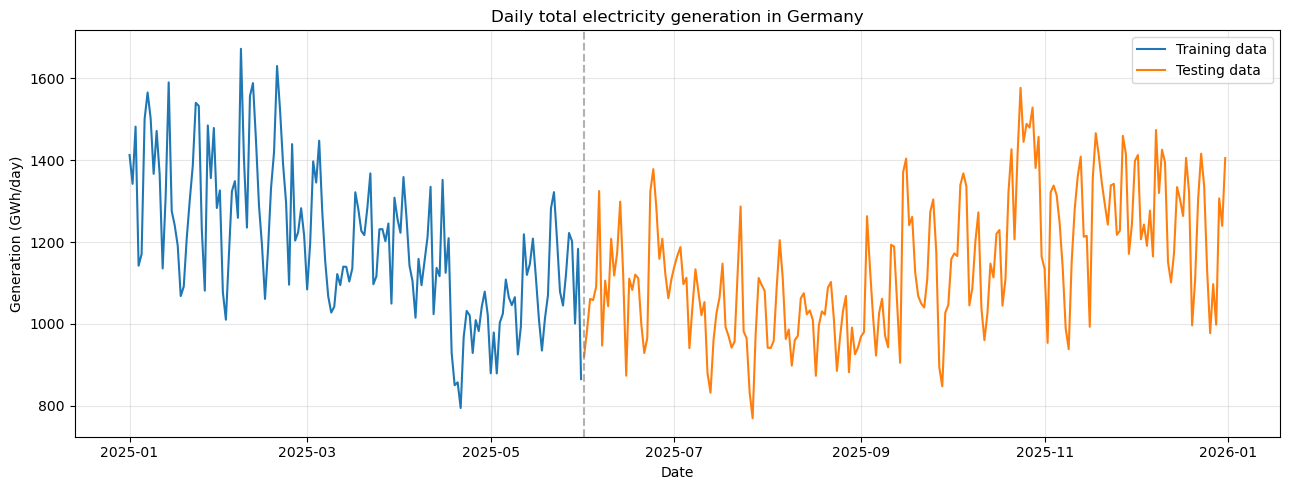

In [24]:
train_y = y[y.index < TEST_START]
test_y = y[y.index >= TEST_START]
print(f"Training: {train_y.index[0].date()} - {train_y.index[-1].date()} ({len(train_y)} days)")
print(f"Testing:  {test_y.index[0].date()} - {test_y.index[-1].date()} ({len(test_y)} days)")

plt.figure(figsize=(13, 5))
plt.plot(train_y.index, train_y, label="Training data")
plt.plot(test_y.index, test_y, label="Testing data")
plt.axvline(pd.Timestamp(TEST_START), color="gray", linestyle="--", alpha=0.6)
plt.title("Daily total electricity generation in Germany")
plt.xlabel("Date")
plt.ylabel("Generation (GWh/day)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


ADF p-value, original series: 0.6359
ADF p-value after seasonal differencing (lag 7): 0.0556
ADF p-value after additional regular difference #1: 0.0000
Selected d = 1, D = 1, m = 7


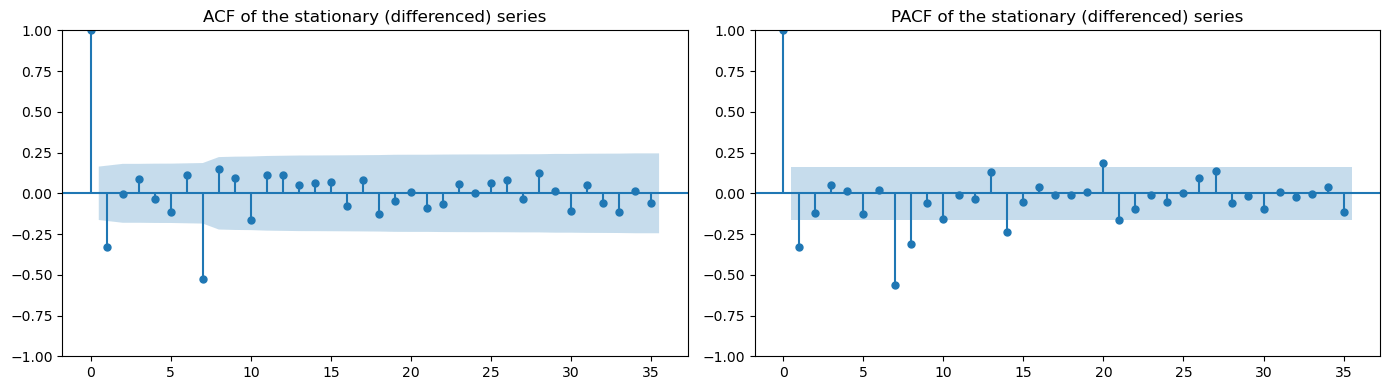

In [25]:
D = 1
adf_p = adfuller(train_y)[1]
print(f"\nADF p-value, original series: {adf_p:.4f}")

d = 0
stationary = train_y.diff(SEASONAL_PERIOD * D).dropna()
print(f"ADF p-value after seasonal differencing (lag {SEASONAL_PERIOD}): {adfuller(stationary)[1]:.4f}")
while adfuller(stationary)[1] > 0.05 and d < 2:
    stationary = stationary.diff().dropna()
    d += 1
    print(f"ADF p-value after additional regular difference #{d}: {adfuller(stationary)[1]:.4f}")
print(f"Selected d = {d}, D = {D}, m = {SEASONAL_PERIOD}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(stationary, lags=35, ax=axes[0])
axes[0].set_title("ACF of the stationary (differenced) series")
plot_pacf(stationary, lags=35, ax=axes[1], method="ywm")
axes[1].set_title("PACF of the stationary (differenced) series")
plt.tight_layout()
plt.show()

In [26]:
candidate_cols = [
    c for c in daily.columns
    if c != "Total generation"
    and not any(k in c.lower() for k in NOT_EXOG_KEYWORDS)
    and any(k in c.lower() for k in EXOG_CANDIDATE_KEYWORDS)
]
if not candidate_cols:
    raise ValueError("No exogenous candidates found - set EXOG_OVERRIDE manually.")
train_daily = daily.loc[train_y.index]
target_diff = train_daily["Total generation"].diff(SEASONAL_PERIOD)

screening = []
for c in candidate_cols:
    x_diff = train_daily[c].diff(SEASONAL_PERIOD)
    corr_diff = target_diff.corr(x_diff)
    corr_level = train_daily["Total generation"].corr(train_daily[c])
    screening.append({
        "Candidate": c,
        "Corr (levels)": corr_level,
        "Corr (differenced)": corr_diff,
        "Abs corr (differenced)": abs(corr_diff),
    })
screening_df = pd.DataFrame(screening).sort_values("Abs corr (differenced)", ascending=False)
print("\nExogenous candidates (training data):")
print(screening_df.drop(columns="Abs corr (differenced)").to_string(index=False, float_format=lambda v: f"{v:.3f}"))

if EXOG_OVERRIDE is not None:
    exog_cols = list(EXOG_OVERRIDE)
else:
    exog_cols = []
    for c in screening_df["Candidate"]:
        too_similar = any(
            abs(train_daily[c].diff(SEASONAL_PERIOD).corr(train_daily[e].diff(SEASONAL_PERIOD))) > 0.8
            for e in exog_cols
        )
        if not too_similar:
            exog_cols.append(c)
        if len(exog_cols) == N_EXOG:
            break
print(f"\nSelected exogenous variables: {exog_cols}")

# Standardise exogenous variables using training statistics only
exog_mean = train_daily[exog_cols].mean()
exog_std = train_daily[exog_cols].std()
exog_scaled = (daily[exog_cols] - exog_mean) / exog_std
exog_scaled = exog_scaled.interpolate(limit=3).bfill().ffill()
train_X = exog_scaled.loc[train_y.index]
test_X = exog_scaled.loc[test_y.index]


Exogenous candidates (training data):
    Candidate  Corr (levels)  Corr (differenced)
 Wind onshore          0.671               0.816
Wind offshore          0.678               0.691
         Load          0.769               0.384
        Solar         -0.486               0.211

Selected exogenous variables: ['Wind onshore', 'Wind offshore']


In [27]:
grid_results = []
for p, q, P, Q in itertools.product(range(0, 3), range(0, 3), range(0, 2), range(0, 2)):
    try:
        fit = SARIMAX(
            train_y,
            order=(p, d, q),
            seasonal_order=(P, D, Q, SEASONAL_PERIOD),
        ).fit(disp=False)
        grid_results.append({
            "order": (p, d, q),
            "seasonal_order": (P, D, Q, SEASONAL_PERIOD),
            "AIC": fit.aic,
            "BIC": fit.bic,
        })
    except Exception as error:
        print(f"SARIMA{(p, d, q)}x{(P, D, Q, SEASONAL_PERIOD)} failed: {error}")

grid_df = pd.DataFrame(grid_results).sort_values("AIC").reset_index(drop=True)
print("\nTop 10 SARIMA candidates (sorted by AIC):")
print(grid_df.head(10).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

best_order = grid_df.loc[0, "order"]
best_seasonal = grid_df.loc[0, "seasonal_order"]
print(f"\nBest SARIMA order by AIC: {best_order} x {best_seasonal}")


Top 10 SARIMA candidates (sorted by AIC):
    order seasonal_order     AIC     BIC
(2, 1, 1)   (1, 1, 1, 7) 1781.71 1799.49
(2, 1, 1)   (0, 1, 1, 7) 1782.56 1797.37
(1, 1, 2)   (0, 1, 1, 7) 1782.66 1797.47
(2, 1, 2)   (1, 1, 1, 7) 1783.23 1803.97
(0, 1, 2)   (1, 1, 1, 7) 1784.30 1799.11
(1, 1, 1)   (0, 1, 1, 7) 1784.37 1796.22
(0, 1, 1)   (1, 1, 1, 7) 1784.52 1796.37
(1, 1, 1)   (1, 1, 1, 7) 1784.65 1799.47
(2, 1, 2)   (0, 1, 1, 7) 1788.36 1806.14
(1, 1, 2)   (1, 1, 1, 7) 1788.46 1806.24

Best SARIMA order by AIC: (2, 1, 1) x (1, 1, 1, 7)


In [28]:
sarima_fit = SARIMAX(
    train_y, order=best_order, seasonal_order=best_seasonal
).fit(disp=False)

sarimax_fit = SARIMAX(
    train_y, exog=train_X, order=best_order, seasonal_order=best_seasonal
).fit(disp=False)

print("\nSARIMA summary")
print(sarima_fit.summary())
print("\nSARIMAX summary")
print(sarimax_fit.summary())

print("\nIn-sample information criteria")
print(f"SARIMA : AIC = {sarima_fit.aic:.2f}, BIC = {sarima_fit.bic:.2f}")
print(f"SARIMAX: AIC = {sarimax_fit.aic:.2f}, BIC = {sarimax_fit.bic:.2f}")


SARIMA summary
                                     SARIMAX Results                                     
Dep. Variable:                  Total generation   No. Observations:                  151
Model:             SARIMAX(2, 1, 1)x(1, 1, 1, 7)   Log Likelihood                -884.855
Date:                           Wed, 21 Oct 2026   AIC                           1781.709
Time:                                   21:32:28   BIC                           1799.486
Sample:                               01-01-2025   HQIC                          1788.933
                                    - 05-31-2025                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4271      0.098      4.357      0.000       0.235       0.619
ar.L2          0.1904      

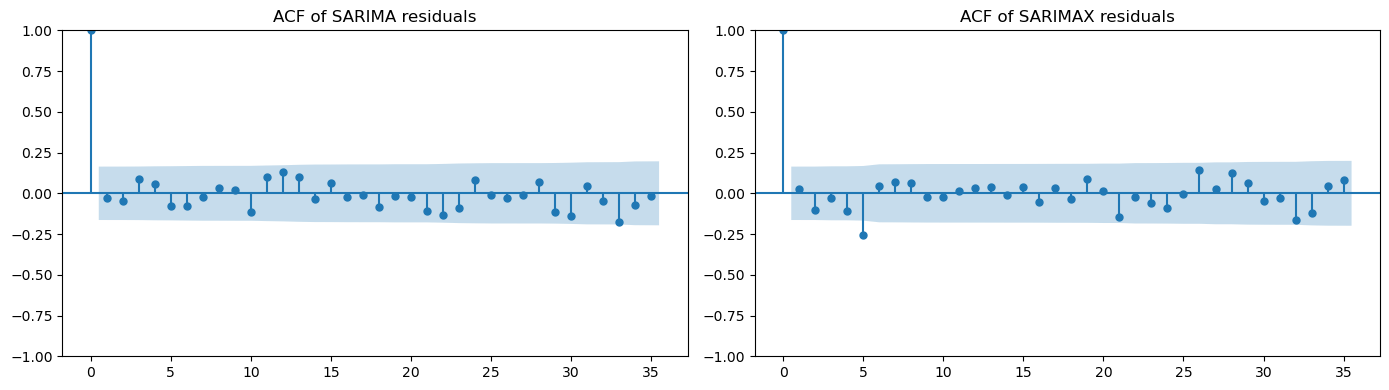

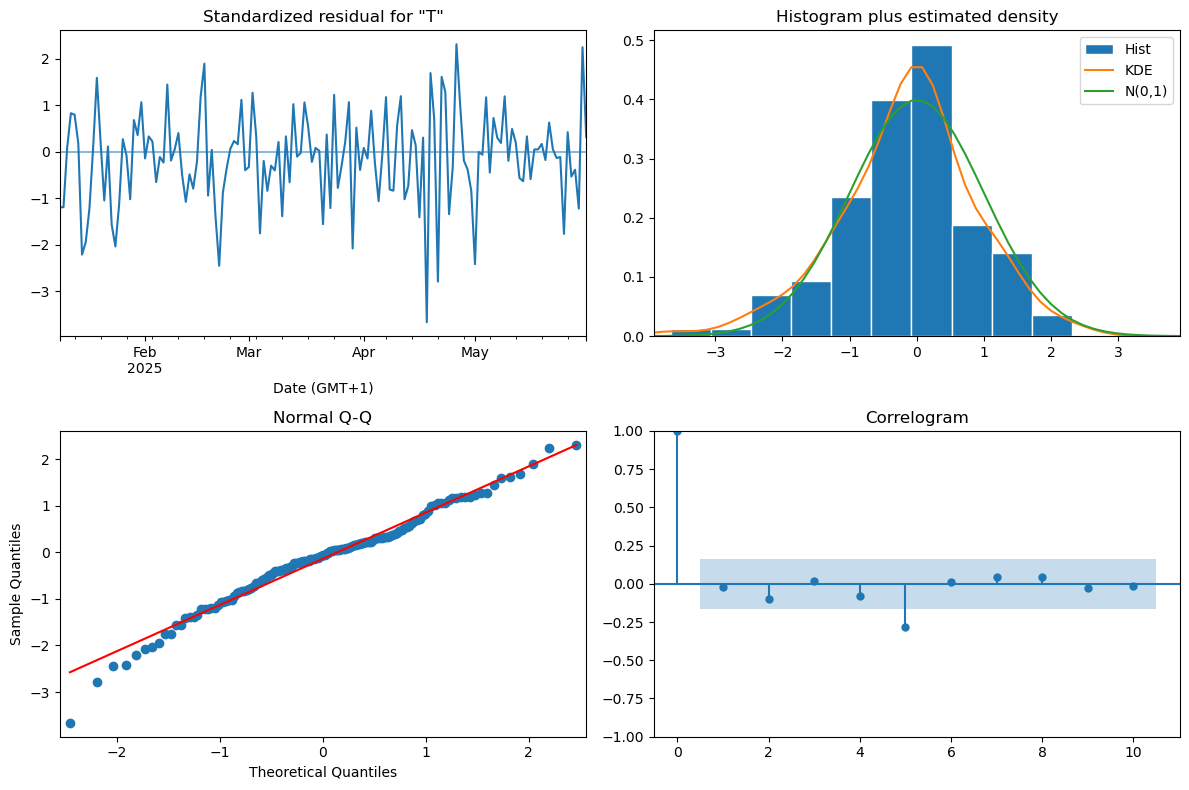


Ljung-Box test - SARIMA residuals
      lb_stat  lb_pvalue
7    4.031943   0.133191
14  12.547115   0.184192
21  16.548979   0.415346
28  23.351972   0.440382
Lag 7: p = 0.1332 - no significant autocorrelation.
Lag 14: p = 0.1842 - no significant autocorrelation.
Lag 21: p = 0.4153 - no significant autocorrelation.
Lag 28: p = 0.4404 - no significant autocorrelation.

Ljung-Box test - SARIMAX residuals
      lb_stat  lb_pvalue
7   14.466664   0.000722
14  15.604614   0.075612
21  21.600472   0.156567
28  30.212263   0.143405
Lag 7: p = 0.0007 - residual autocorrelation may remain.
Lag 14: p = 0.0756 - no significant autocorrelation.
Lag 21: p = 0.1566 - no significant autocorrelation.
Lag 28: p = 0.1434 - no significant autocorrelation.


In [29]:
burn_in = d + D * SEASONAL_PERIOD   # first residuals are affected by differencing
n_params = best_order[0] + best_order[2] + best_seasonal[0] + best_seasonal[2]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, name, fit in zip(axes, ["SARIMA", "SARIMAX"], [sarima_fit, sarimax_fit]):
    plot_acf(fit.resid.iloc[burn_in:], lags=35, ax=ax)
    ax.set_title(f"ACF of {name} residuals")
plt.tight_layout()
plt.show()

sarimax_fit.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()

for name, fit in [("SARIMA", sarima_fit), ("SARIMAX", sarimax_fit)]:
    lb = acorr_ljungbox(
        fit.resid.iloc[burn_in:],
        lags=[7, 14, 21, 28],
        model_df=n_params,
        return_df=True,
    )
    print(f"\nLjung-Box test - {name} residuals")
    print(lb)
    for lag, row in lb.iterrows():
        if pd.notna(row["lb_pvalue"]) and row["lb_pvalue"] > 0.05:
            print(f"Lag {lag}: p = {row['lb_pvalue']:.4f} - no significant autocorrelation.")
        else:
            print(f"Lag {lag}: p = {row['lb_pvalue']:.4f} - residual autocorrelation may remain.")

In [30]:
steps = len(test_y)

multi_sarima = sarima_fit.get_forecast(steps=steps).predicted_mean
multi_sarimax = sarimax_fit.get_forecast(steps=steps, exog=test_X).predicted_mean
multi_sarima.index = test_y.index
multi_sarimax.index = test_y.index

# Seasonal naive baseline: repeat the last training week
last_week = train_y.iloc[-SEASONAL_PERIOD:].values
multi_naive = pd.Series(np.resize(last_week, steps), index=test_y.index)

sarima_ext = sarima_fit.extend(test_y)
sarimax_ext = sarimax_fit.extend(test_y, exog=test_X)
# The extended results cover only the new (test) sample; their fitted values are
# one-step-ahead predictions made with the parameters estimated on the training data.
roll_sarima = pd.Series(np.asarray(sarima_ext.fittedvalues), index=test_y.index)
roll_sarimax = pd.Series(np.asarray(sarimax_ext.fittedvalues), index=test_y.index)
roll_naive = y.shift(SEASONAL_PERIOD).loc[test_y.index]


def evaluate(forecasts):
    rows = []
    for name, f in forecasts.items():
        mae = mean_absolute_error(test_y, f)
        rmse = np.sqrt(mean_squared_error(test_y, f))
        mape = np.mean(np.abs((test_y - f) / test_y)) * 100
        rows.append({"Model": name, "MAE": mae, "RMSE": rmse, "MAPE [%]": mape})
    return pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)


multi_results = evaluate({
    "SARIMA": multi_sarima,
    "SARIMAX": multi_sarimax,
    "Seasonal naive": multi_naive,
})
roll_results = evaluate({
    "SARIMA": roll_sarima,
    "SARIMAX": roll_sarimax,
    "Seasonal naive": roll_naive,
})

print(f"\nMulti-step forecast ({TEST_START} - {test_y.index[-1].date()}), units: GWh/day")
print(multi_results.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print("\nRolling one-step-ahead forecast, units: GWh/day")
print(roll_results.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

mae_sarima = multi_results.set_index("Model").loc["SARIMA", "MAE"]
mae_sarimax = multi_results.set_index("Model").loc["SARIMAX", "MAE"]
improvement = (1 - mae_sarimax / mae_sarima) * 100
print(f"\nMulti-step MAE reduction of SARIMAX relative to SARIMA: {improvement:.1f} %")


Multi-step forecast (2025-06-01 - 2025-12-31), units: GWh/day
         Model     MAE    RMSE  MAPE [%]
       SARIMAX  59.169  72.161     5.280
Seasonal naive 151.212 184.895    12.994
        SARIMA 354.707 436.468    29.116

Rolling one-step-ahead forecast, units: GWh/day
         Model     MAE    RMSE  MAPE [%]
       SARIMAX  38.054  49.041     3.394
        SARIMA  87.297 112.817     7.484
Seasonal naive 127.288 165.486    11.148

Multi-step MAE reduction of SARIMAX relative to SARIMA: 83.3 %


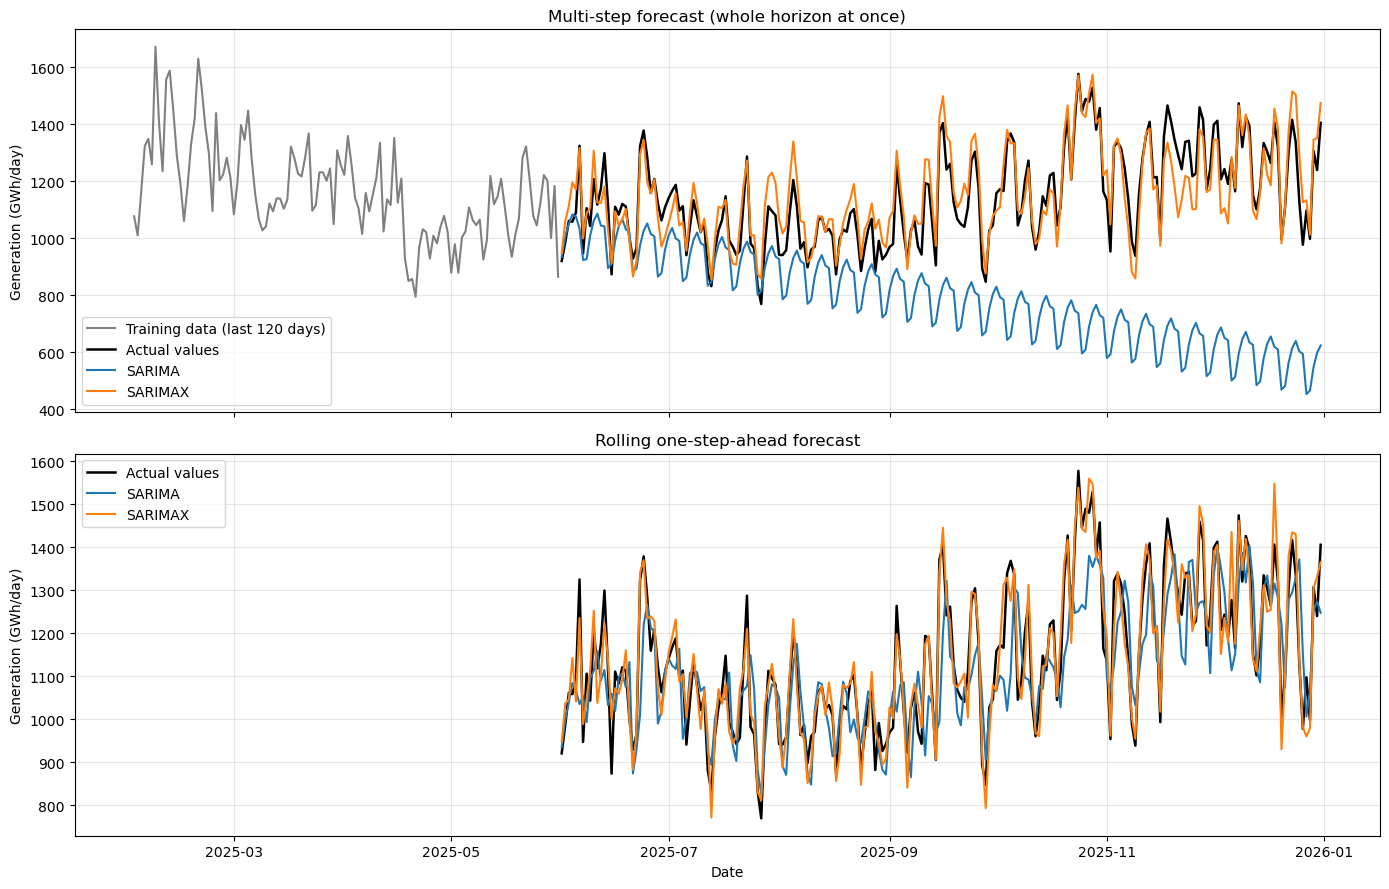

In [31]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].plot(train_y.index[-120:], train_y.iloc[-120:], color="gray", label="Training data (last 120 days)")
axes[0].plot(test_y.index, test_y, color="black", linewidth=1.8, label="Actual values")
axes[0].plot(multi_sarima.index, multi_sarima, label="SARIMA")
axes[0].plot(multi_sarimax.index, multi_sarimax, label="SARIMAX")
axes[0].set_title("Multi-step forecast (whole horizon at once)")
axes[0].set_ylabel("Generation (GWh/day)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(test_y.index, test_y, color="black", linewidth=1.8, label="Actual values")
axes[1].plot(roll_sarima.index, roll_sarima, label="SARIMA")
axes[1].plot(roll_sarimax.index, roll_sarimax, label="SARIMAX")
axes[1].set_title("Rolling one-step-ahead forecast")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Generation (GWh/day)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()